In [ ]:
!pip install category_encoders

In [ ]:
# ==========================================
# 1. Librerías Estándar y Utilidades
# ==========================================
import io
import hashlib
import itertools
import requests
import re

# ==========================================
# 2. Manipulación de Datos y Matemáticas
# ==========================================
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, randint, loguniform, uniform

# ==========================================
# 3. Visualización
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 4. Preprocesamiento, Encoders y Pipelines
# ==========================================
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    FunctionTransformer,
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    OrdinalEncoder,
    OneHotEncoder,
    TargetEncoder, # TargetEncoder nativo de Scikit-Learn
    label_binarize
)
# Alias para evitar conflicto de nombres con el TargetEncoder de sklearn
from category_encoders import CountEncoder, TargetEncoder as CE_TargetEncoder

# ==========================================
# 5. Modelos de Machine Learning
# ==========================================
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from xgboost import XGBRegressor


# ==========================================
# 6. Selección de Modelos e Inspección
# ==========================================
from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV,
    GroupKFold
)
from sklearn.inspection import permutation_importance

# ==========================================
# 7. Métricas de Evaluación
# ==========================================
from sklearn.metrics import (
    # Métricas de Clasificación
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,

    # Métricas de Regresión
    mean_squared_error,
    mean_absolute_error,
    r2_score,

    # Métricas de Clustering
    silhouette_score
)
from sklearn.base import clone
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from sklearn.model_selection import GroupKFold, cross_validate

from lightgbm import LGBMRegressor
from xgboost import XGBRegressor


#Carga del dataset

In [ ]:
url = "https://raw.githubusercontent.com/Mapabaoy12/EncargoMachineLearning2/refs/heads/main/dataML/Spotify_Tracks_Dataset.csv"
HASH_ORIGINAL = "b202fa49909b2d5cef71a04b1d21243cfeb36414535f2ca9272aa646721177bd"

In [ ]:
try:
    # intento de descarga y validación
    response = requests.get(url)
    response.raise_for_status()  # verifica que url funcione y no de error

    contenido_raw = response.content
    hash_calculado = hashlib.sha256(contenido_raw).hexdigest()

    if hash_calculado == HASH_ORIGINAL:
        print("AUDITORÍA EXITOSA: Integridad de procedencia garantizada.")
        df = pd.read_csv(io.BytesIO(contenido_raw))
        print("Dataset cargado correctamente.")
    else:
        # si hash no coincide, da un error manual
        raise ValueError("El hash no coincide. El archivo ha sido modificado o está corrupto.")

except Exception as e:
    # captura cualquier error y detiene el proceso
    raise RuntimeError(f"FALLO CRÍTICO: No se pudo procesar el dataset. Detalle: {e}")

AUDITORÍA EXITOSA: Integridad de procedencia garantizada.
Dataset cargado correctamente.


In [ ]:
# En todo este proyecto se trabajará con random_state = 42
random_state=42

In [ ]:
# Depuración de registros nulos y filas redundantes
df_clean = df.dropna(subset=['track_id', 'artists', 'track_name', 'popularity']).copy()
df_clean.drop(columns=['Unnamed: 0'], errors='ignore', inplace=True)

# Resolución de duplicados a nivel de track único
df_clean = df_clean.groupby('track_id', as_index=False).first()

# Conversión temporal e ingeniería de características vectorizada
df_clean["duration_s"] = df_clean["duration_ms"] / 1000.0
df_clean['valence_instrumentalness_sum'] = df_clean['valence'] + df_clean['instrumentalness']
df_clean['artista_principal'] = df_clean['artists'].astype(str).str.split(';').str[0].str.strip()
df_clean['es_colaboracion'] = df_clean['artists'].astype(str).str.contains(';').astype(int)

In [ ]:
# ---------- Limpieza de nombres de columnas para LightGBM ----------
def limpiar_nombres(df):
    """LightGBM falla con caracteres como , : [ ] { } " en los nombres de columnas.
    Los nombres de artistas los traen (ej: 'Tyler, The Creator')."""
    df = df.copy()
    nuevas, vistos = [], {}
    for c in df.columns:
        c = re.sub(r'[^0-9a-zA-Z_]+', '_', str(c))
        if c in vistos:                 # evita nombres duplicados tras la limpieza
            vistos[c] += 1
            c = f"{c}_{vistos[c]}"
        else:
            vistos[c] = 0
        nuevas.append(c)
    df.columns = nuevas
    return df

In [ ]:
class WinsorizerRobusto(BaseEstimator, TransformerMixin):
    """
    Ajusta los cuantiles de recorte exclusivamente en fit()
    y los aplica de forma determinista en transform().
    """
    def __init__(self, limits=(0.05, 0.05)):
        self.limits = limits

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        self.lower_bounds_ = X_df.quantile(self.limits[0]).to_numpy()
        self.upper_bounds_ = X_df.quantile(1.0 - self.limits[1]).to_numpy()
        self.n_features_in_ = X_df.shape[1]
        return self

    def transform(self, X):
        X_array = np.asarray(X, dtype=np.float64)
        return np.clip(X_array, self.lower_bounds_, self.upper_bounds_)

    def get_feature_names_out(self, input_features=None):
        return input_features

In [ ]:
def evaluar_modelo_clasificacion(modelo: BaseEstimator, X_train: np.array, X_test: np.array, y_train: np.array, y_test: np.array):
  """
  Retorna las métricas del modelo

  Parámetros
  ----------
  modelo : BaseEstimator
    Modelo a evaluar.
  X_train : np.array
    Conjunto de datos de entrenamiento.
  X_test : np.array
    Conjunto de datos de prueba.
  y_train : np.array
    Etiquetas de entrenamiento.
  y_test : np.array
    Etiquetas de prueba
  Returns
  -------
  dict
    Diccionario con las métricas del modelo.

  """
  #modelo.fit(X_train, y_train)

  y_pred = modelo.predict(X_test)
  y_prob = modelo.predict_proba(X_test)

  return {
    "accuracy": accuracy_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred, average='weighted'),
    "precision": precision_score(y_test, y_pred, zero_division=0, average='weighted'),
    "recall": recall_score(y_test, y_pred, average='weighted'),
    "roc_auc": roc_auc_score(y_test, y_prob, multi_class='ovr', average='weighted')
  }

In [ ]:
def evaluar_modelo_regresion(modelo: BaseEstimator, X_train: np.array, X_test: np.array, y_train: np.array, y_test: np.array):
  """
  Retorna las métricas del modelo

  Parámetros
  ----------
  modelo : BaseEstimator
    Modelo a evaluar.
  X_train : np.array
    Conjunto de datos de entrenamiento.
  X_test : np.array
    Conjunto de datos de prueba.
  y_train : np.array
    Etiquetas de entrenamiento.
  y_test : np.array
    Etiquetas de prueba
  Returns
  -------
  dict
    Diccionario con las métricas del modelo.

  """
  modelo.fit(X_train, y_train)

  y_pred = modelo.predict(X_test)

  return {
    "mean_absolute_error": mean_absolute_error(y_test, y_pred),
    "r2_score": r2_score(y_test, y_pred)
  }

In [ ]:
class CorrelationFilter(BaseEstimator, TransformerMixin):
  """
  Eliminación de variables correlacionadas

  Parámetros
  ----------
  BaseEstimator : Clase base para estimadores en scikit-learn.
  TransformerMixin : Clase base para transformadores en scikit-learn.

  Atributos
  ---------
  columns_to_drop_ : array-like
    Nombres de las columnas a eliminar.
  threshold : float
    Umbral de correlación.
  Returns
  -------
  DataFrame
    Conjunto de datos sin variables correlacionadas.
  """
  def __init__(self, threshold=0.9):
    self.threshold = threshold
    self.columns_to_drop_ = None

  def fit(self, X, y=None):
    X_df = pd.DataFrame(X)

    corr_matrix = X_df.corr().abs()
    upper = corr_matrix.where(
      np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )

    self.columns_to_drop_ = [
        col for col in upper.columns if any(upper[col] > self.threshold)
    ]

    return self

  def transform(self, X):
    X_df = pd.DataFrame(X)
    X_filtered = X_df.drop(columns=self.columns_to_drop_, errors="ignore")
    return X_filtered.values

In [ ]:
class DataFrameConverter(BaseEstimator, TransformerMixin):
  """
  Convierte un array en un DataFrame

  Parámetros
  ----------
  BaseEstimator : Clase base para estimadores en scikit-learn.
  TransformerMixin : Clase base para transformadores en scikit-learn.

  Atributos
  ---------
  feature_names_ : array-like
    Nombres de las columnas.
  Returns
  -------
  DataFrame
    Conjunto de datos con nombres de columnas.
  """
  def __init__(self, preprocessor):
    self.preprocessor = preprocessor
    self.feature_names_ = None

  def fit(self, X, y=None):
    # Obtener nombres después de fit del preprocessor
    self.feature_names_ = self.preprocessor.get_feature_names_out()
    return self

  def transform(self, X):
    return pd.DataFrame(X, columns=self.feature_names_)

#Análisis exploratorio de los datos

El listado de variables que forman parte del dataset es el siguiente:

"track_id": Identificador de Spotify para la canción

"artists": Artista de la canción, si hay más de uno se separa con ;

"album_name": Álbum donde la canción aparece

"track_name": Nombre de la pista de audio musical

"popularity": Popularidad de la canción bajo una puntuación de 0 a 100

"duration_ms": Duración en segundos

"explicit": Contenido explícito de la canción (letras), variable False o True

"danceability": Escala que denomina qué tan bailable es una canción de 0.0 a 1.0

"energy": Intensidad de la canción medida en 0.0 a 1.0

"key": Tonalidad / escala de notas de la canción, del 0 al 11

"loudness": Sonoridad de la canción medida en decibeles

"mode": Escala melódica de la canción

"speechiness": Cantidad de palabras en escala de 0.0 a 1.0

"acousticness": Escala de 0.0 a 1.0 para medir si una canción es acústica

"instrumentalness": Escala de 0.0 a 1.0 para medir si una canción es más instrumental

"liveness": Escala de 0.0 a 1.0 para medir si la canción fue cantada en live

"valence": Positividad medida en 0.0 a 1.0

"tempo": Tempo estimado de la canción

"time_signature": Cantidad de beats en una canción

"track_genre": Género de la canción

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

In [ ]:
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [ ]:
#fila(s) con valores nulos
filas_con_nulos = df[df.isna().any(axis=1)]
filas_con_nulos

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


No se puede hacer nada con este track sin nombre, artista, popularidad, etc etc. Lo mejor es borrarlo y se tendrá 13999/13999 registros sin nulos.

In [ ]:
# eliminar track_id 1kR4gIb7nGxHPI3D2ifs59 del df ya que es el único nulo
df.drop(df[df['track_id'] == '1kR4gIb7nGxHPI3D2ifs59'].index, inplace=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 113999 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        113999 non-null  int64  
 1   track_id          113999 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        113999 non-null  int64  
 6   duration_ms       113999 non-null  int64  
 7   explicit          113999 non-null  bool   
 8   danceability      113999 non-null  float64
 9   energy            113999 non-null  float64
 10  key               113999 non-null  int64  
 11  loudness          113999 non-null  float64
 12  mode              113999 non-null  int64  
 13  speechiness       113999 non-null  float64
 14  acousticness      113999 non-null  float64
 15  instrumentalness  113999 non-null  float64
 16  liveness          113999 

In [ ]:
# Se descarta la columna "Unnamed: 0" del dataset por la nula relevancia predictiva
df.drop(columns=['Unnamed: 0'], errors='ignore', inplace=True)

In [ ]:
# Conversión de milisegundos a segundos y renombramiento

df["duration_ms"] = df["duration_ms"] / 1000
df.rename(columns={"duration_ms": "duration_s"}, inplace=True)

In [ ]:
# Cantidad total de géneros únicos (excluyendo nulos por defecto)
total_generos = df['track_genre'].nunique()
print(f"Total de géneros únicos: {total_generos}")

Total de géneros únicos: 114


In [ ]:
# buscar duplicado considerando track_id y track_genre
duplicados_id = df[df.duplicated(subset=['track_id', 'track_genre'], keep=False)].sort_values(by='track_id')
duplicados_id.shape

(894, 20)

In [ ]:
#Eliminación de duplicados que tengan el "track_id" y "track_genre" igual
df.drop_duplicates(subset=['track_id', 'track_genre'], inplace=True)


In [ ]:
# correlación de variables numéricas con respecto a "popularity"
df.select_dtypes(include=['number']).corrwith(df['popularity'],method='spearman').sort_values(ascending=False)

,0
popularity,1.000000
time_signature,0.035834
loudness,0.033146
duration_s,0.026528
danceability,0.025760
tempo,0.015990
acousticness,0.011263
key,-0.002860
liveness,-0.008356
mode,-0.015554


In [ ]:
#Agrupamos el dataset por identificador unico, aplicando .first()
#para conservar unicamente la primera aparicion
df = df.groupby('track_id', as_index=False).first()

#Feature engineering

In [ ]:
#La columna 'artist' agrupa multiples interpretes en una sola cadena de texto lo que
#provoca una alta cardinalidad y no concede el valor real de los artistas.
#Para evitar esto se crean dos variables 'artista_principal' y 'es_colaboracion'

#Aisla al primer interprete de las canciones garantizando tener una muestra estadistica solida
df['artista_principal'] = df['artists'].astype(str).str.split(';').str[0].str.strip()
#Rescata la presencia de artistas secuandarios para medir el impulso que genera la union de diferentes artistas
df['es_colaboracion'] = df['artists'].astype(str).str.contains(';').astype(int)


In [ ]:
# variables cuantitativas y cualitativas
variables_cuantitativas = ["popularity", "duration_s", "danceability", "energy", "key", "loudness", "mode", "speechiness", "acousticness",  "instrumentalness", "liveness", "tempo", "time_signature"]
variables_cualitativas = [ "artists", "album_name", "track_name", "track_genre", "artista_principal", "es_colaboracion"]


In [ ]:
df["explicit"] = df["explicit"].astype(int)   # True/False -> 1/0

In [ ]:
# Analizar correlación de variables categóricas con popularity, para eso se pasa popularity a categórica
# 1. Categorizar la popularidad (ej. por umbral de negocio)
df['popularity_cat'] = pd.qcut(df['popularity'], q=5)

def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    return np.sqrt(chi2 / (n * min(r - 1, k - 1)))

# 2. Calcular solo sobre variables de cardinalidad manejable (como track_genre)
#v_cramer = cramers_v(df['track_genre'], df['popularity_cat'])
#print(f"V de Cramér (track_genre vs popularity_cat): {v_genre:.4f}")

for col in variables_cualitativas:
    v_cramer = cramers_v(df[col], df['popularity_cat'])
    print(f"V de Cramér ({col} vs popularity_cat): {v_cramer:.4f}")


V de Cramér (artists vs popularity_cat): 0.8423
V de Cramér (album_name vs popularity_cat): 0.9180
V de Cramér (track_name vs popularity_cat): 0.9417
V de Cramér (track_genre vs popularity_cat): 0.5703
V de Cramér (artista_principal vs popularity_cat): 0.7902
V de Cramér (es_colaboracion vs popularity_cat): 0.1025


In [ ]:
# ver las categorías que generó para popularity categórico
df["popularity_cat"].unique()

[(40.0, 52.0], (15.0, 26.0], (52.0, 100.0], (-0.001, 15.0], (26.0, 40.0]]
Categories (5, interval[float64, right]): [(-0.001, 15.0] < (15.0, 26.0] < (26.0, 40.0] <
                                           (40.0, 52.0] < (52.0, 100.0]]

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89740 entries, 0 to 89739
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   track_id           89740 non-null  object  
 1   artists            89740 non-null  object  
 2   album_name         89740 non-null  object  
 3   track_name         89740 non-null  object  
 4   popularity         89740 non-null  int64   
 5   duration_s         89740 non-null  float64 
 6   explicit           89740 non-null  int64   
 7   danceability       89740 non-null  float64 
 8   energy             89740 non-null  float64 
 9   key                89740 non-null  int64   
 10  loudness           89740 non-null  float64 
 11  mode               89740 non-null  int64   
 12  speechiness        89740 non-null  float64 
 13  acousticness       89740 non-null  float64 
 14  instrumentalness   89740 non-null  float64 
 15  liveness           89740 non-null  float64 
 16  vale

# Visualizaciones y hallazgos

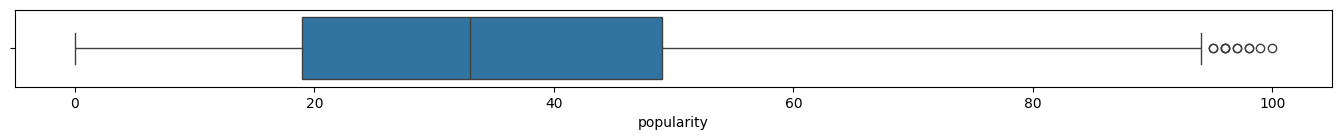

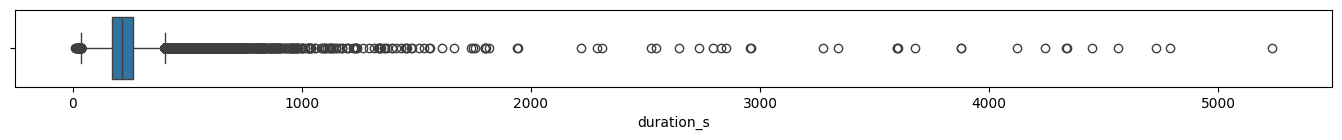

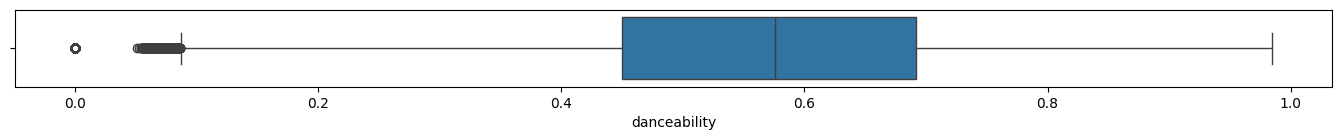

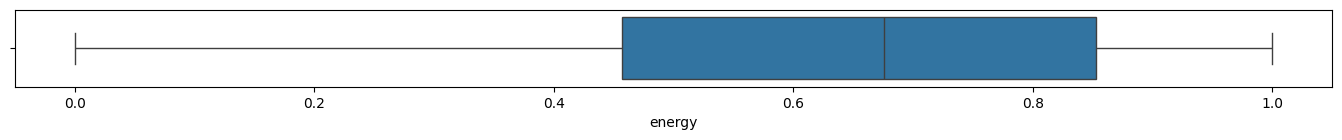

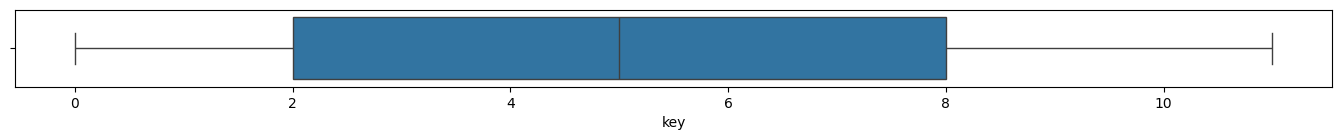

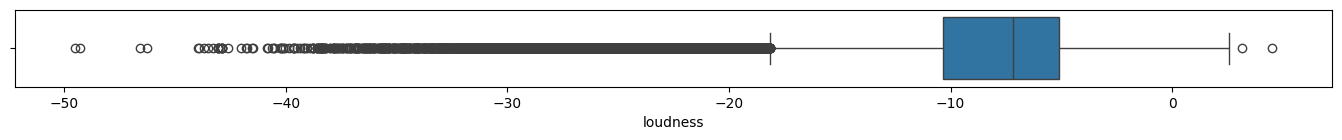

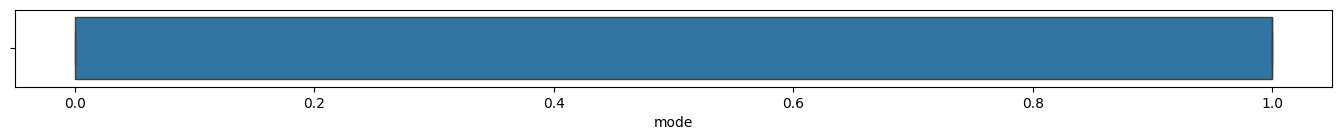

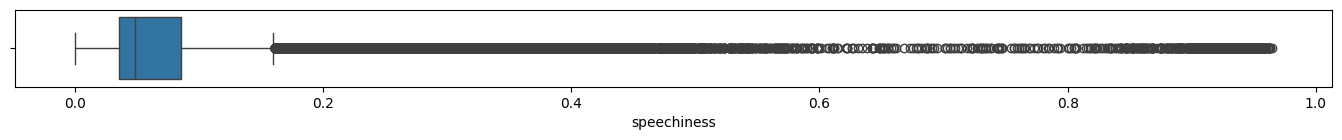

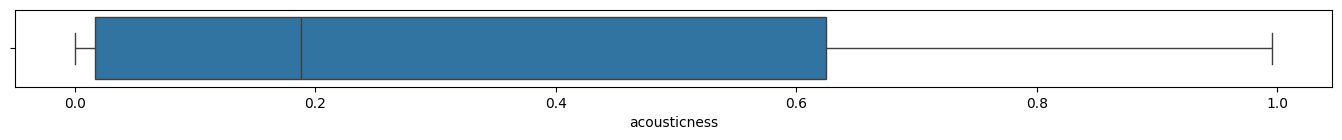

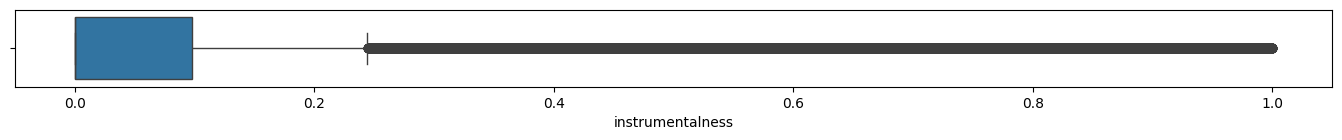

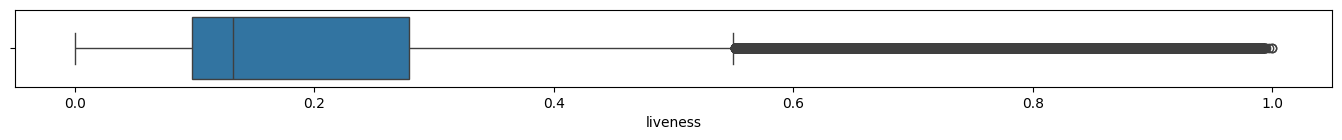

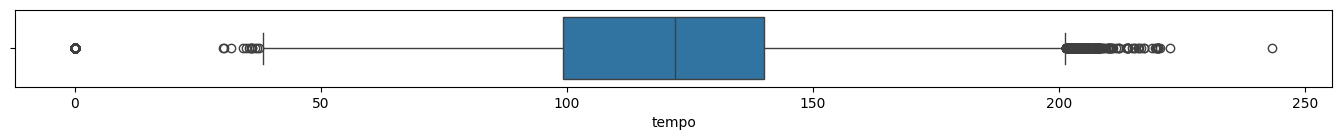

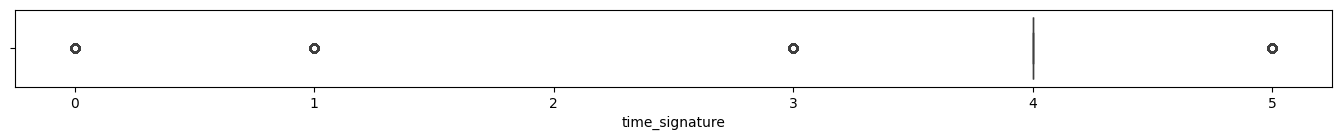

In [ ]:
#Comprobación de outliers
for col in variables_cuantitativas:
    plt.figure(figsize = (17,1))
    sns.boxplot(data=df[variables_cuantitativas], x = col)
    #Este ciclo for nos permite visualisar las columnas numéricas con su visualización bajo boxplot para ver la presencia de outliers dentro de nuestros datos



El gráfico de bloxplot nos permite ver la cantidad de valores outliers y distribuciones de cada variable, cada uno con su respectiva escala.
Cajas como danceability y energy se encuentran inclinados hacia la derecha, debido a que la mayoría de canciones están hechas para ser dinámicas y rítmicas.

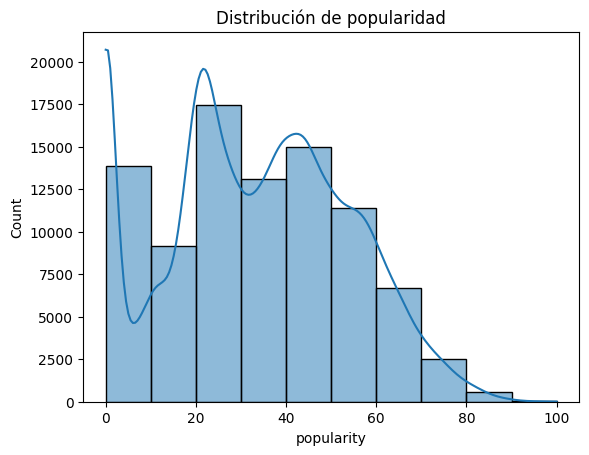

In [ ]:
# Gráfico de histograma con líneas para distribución de popularidad
sns.histplot(data=df, x="popularity", bins=10, kde=True)
plt.title("Distribución de popularidad")
plt.show()

Se presencia una distribución hacia la izquierda con una acumulación masiva de canciones con popularidad 0, dándonos a entender que en la totalidad de las canciones la mayoría presenta un rango de popularidad de [0-50], mientras que hay un número reducido de canciones con un umbral de popularidad del [51-100], desde ahí va en declive.
El gráfico al no comportarse como una campana de Gauss perfecta, teniendo en sí, múltiples jorobas, dejando en criterio que las canciones no se comportan de forma normal o predecible.

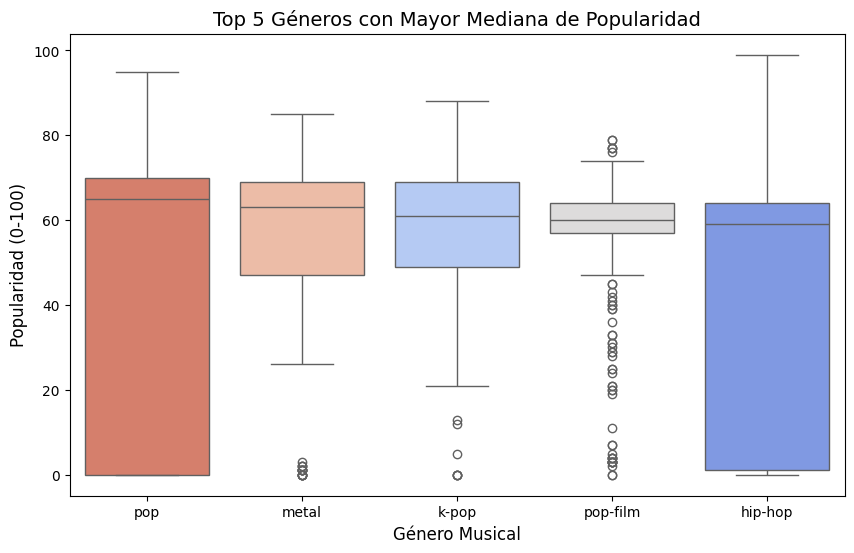

In [ ]:
# 1. Identificar los 5 géneros con la mayor mediana de popularidad
top_5_generos = df.groupby('track_genre')['popularity'].median().nlargest(5).index

# 2. Filtrar el dataset para conservar solo las filas de esos 5 géneros
df_top5 = df[df['track_genre'].isin(top_5_generos)]

# 3. Generar el gráfico corregido
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_top5,
    x='track_genre',
    y='popularity',
    hue='track_genre',     # Asigna la variable categórica a hue
    order=top_5_generos,
    palette='coolwarm',
    legend=False           # Oculta la leyenda redundante
)

# 4. Ajustes estéticos para la presentación
plt.title('Top 5 Géneros con Mayor Mediana de Popularidad', fontsize=14)
plt.xlabel('Género Musical', fontsize=12)
plt.ylabel('Popularidad (0-100)', fontsize=12)
plt.show()

Géneros como el pop y hip-hop presentan rangos intercuartiles más largos a comparación de los otros, estos abarcan desde el éxito total hasta el fracaso absoluto, significando que invertir en estos conlleva una apuesta de alto riesgo ya que no garantizan popularidad.
El k-pop y pop-film presentan cajas compactas teniendo una mediana alta y dispersión baja dando segurar como mercado seguro y estable.
A pesar de la estabilidad de pop-film, chill o k-pop se hace presencia de gran cantidad de outliers cercanos a una popularidad baja, concientizando que el género no basta por si solo para medir la popularidad y se necesitan de otras variables.

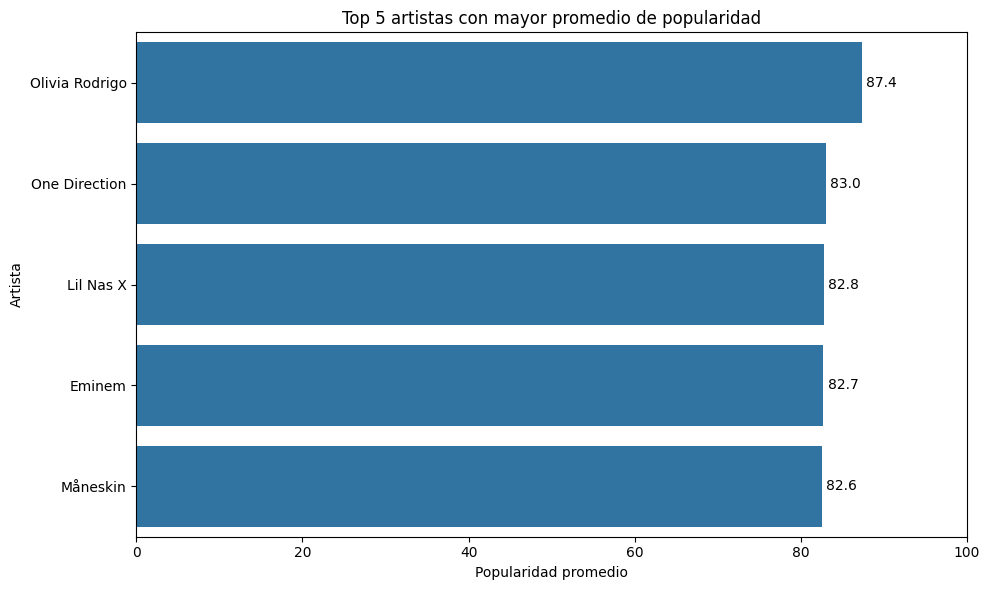

In [ ]:
#Gráfico de barras para los 5 artistas con mayor popularidad promedio
# Calcular cantidad de canciones y popularidad promedio por artista
artistas = (
    df.groupby('artista_principal')
      .agg(
          promedio_popularidad=('popularity', 'mean'),
          cantidad_canciones=('track_id', 'count')
      )
      .query('cantidad_canciones >= 5')
      .sort_values('promedio_popularidad', ascending=False)
      .head(5)
      .reset_index()
)
# Visualización
plt.figure(figsize=(10, 6))
sns.barplot(
    data=artistas,
    x='promedio_popularidad',
    y='artista_principal'
)
plt.title('Top 5 artistas con mayor promedio de popularidad')
plt.xlabel('Popularidad promedio')
plt.ylabel('Artista')
plt.xlim(0, 100)
# Mostrar valor sobre cada barra
for i, valor in enumerate(artistas['promedio_popularidad']):
    plt.text(
        valor + 0.5,
        i,
        f'{valor:.1f}',
        va='center'
    )
plt.tight_layout()
plt.show()

En el top 5, se encuentra Olivia Rodrigo liderando con 87.4 como la artista con mayor promedio de popularidad, siguiendo The Kid LAROI con 85.2 y Chris Brown con 84.0, demostrando cifras competitivas en una escala del 0 al 100.
Esto asegura que el artista contiene un peso considerable en las reproducciones, independiente de otras variables.
Considerando la poca escala de éxito dentro del dataset, los artistas mencionados representan los outliers de éxito extremo.


#Preprocesamiento

### Justificación de Selección y Descarte de Variables

La selección final de características responde a los hallazgos estadísticos del Análisis Exploratorio de Datos (EDA) y a la necesidad de entregar predictores con señal real, evitando introducir ruido o sobreajuste (*overfitting*) en el modelo.

---

### 1. Variables Seleccionadas para el Modelo

* **`artista_principal` (Target Encoding):**
  * Presenta la asociación categórica más determinante del catálogo ($V$ de Cramér $\approx 0.7902$).
  * El reconocimiento comercial y la base de oyentes del músico constituyen el factor individual de mayor poder explicativo del éxito. Se codifica mediante *Target Encoding* continuo regularizado para capturar su impacto reduciendo la dimensionalidad a una sola columna sin inducir sobreajuste.

* **`track_genre` (Target Encoding):**
  * Registra una fuerte asociación estadística frente a la popularidad ($V$ de Cramér $\approx 0.5703$).
  * El género define las pautas de consumo, posicionamiento en playlists y visibilidad en la plataforma. Tras consolidar los 26 géneros infrecuentes bajo la categoría `'otros'` (dejando 88 grupos representativos), se procesa con *Target Encoding* para entregar al modelo una señal continua y directa del impacto del estilo musical sin dispersar los árboles en 88 columnas binarias.

* **`es_colaboracion` (Numérica / Binaria):**
  * Muestra una asociación moderada con el target ($V$ de Cramér $\approx 0.1025$).
  * Modela la tracción comercial adicional generada por lanzamientos conjuntos (*feats*), los cuales expanden la audiencia compartida y favorecen el alcance algorítmico.

* **Variables acústicas continuas:**: Se utilizaron todas las variables contínuas, ya que como se utilizará modelos de ensamble, existe la posibilidad de que un modelo haga descubrimientos que no tengan que ver con la correlación con respecto a la variable objetivo. Algunas de esas variables son:
  * **`instrumentalness` ($r \approx -0.0783$):** Es el atributo de audio con la mayor correlación negativa frente a la popularidad. La marcada penalización lineal de temas instrumentales refleja la preferencia masiva del público por producciones con presencia vocal.
  * **`speechiness` ($r \approx -0.0681$):** Registra una asociación inversa relevante, permitiendo al algoritmo diferenciar entre canciones melódicas convencionales y formatos con alta densidad de palabras o contenido hablado.
  * **`valence` ($r \approx -0.0425$):** Refleja la positividad o estado anímico musical. Mantiene una magnitud de correlación superior al 4%, capturando matices emocionales vinculados a las preferencias de los usuarios.
  * **`time_signature` ($r \approx +0.0358$):** Métrica rítmica asociada a la cadencia y métrica de compás. Aunque su variabilidad es acotada, supera el umbral del 3% y aporta regularidad estructural a las pistas.
  * **`loudness` ($r \approx +0.0331$):** Indicador de potencia sonora en decibeles. Pistas con mayor sonoridad y masterización comercial presentan una ligera correlación positiva con el target.


---

### 2. Justificación de Variables Descartadas

* **Identificadores y textos de alta cardinalidad (`track_id`, `track_name`, `album_name`, `artists` original):**
  * Si bien registran valores de $V$ de Cramér elevados (entre 0.83 y 0.94), esto corresponde a un artefacto matemático debido a que prácticamente cada fila posee un identificador único.
  * Su inclusión provocaría memorización espuria (*data leakage* / sobreajuste severo), impidiendo que el modelo generalice frente a nuevas canciones.


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89740 entries, 0 to 89739
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   track_id           89740 non-null  object  
 1   artists            89740 non-null  object  
 2   album_name         89740 non-null  object  
 3   track_name         89740 non-null  object  
 4   popularity         89740 non-null  int64   
 5   duration_s         89740 non-null  float64 
 6   explicit           89740 non-null  int64   
 7   danceability       89740 non-null  float64 
 8   energy             89740 non-null  float64 
 9   key                89740 non-null  int64   
 10  loudness           89740 non-null  float64 
 11  mode               89740 non-null  int64   
 12  speechiness        89740 non-null  float64 
 13  acousticness       89740 non-null  float64 
 14  instrumentalness   89740 non-null  float64 
 15  liveness           89740 non-null  float64 
 16  vale

"track_id", "track_name", "artists", "album_name", "popularity", "popularity_cat"

In [ ]:
#Enrutamiento de Características post-análisis
cols_num = ['duration_s', 'danceability', 'energy', 'key', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']
cols_bin = ['es_colaboracion', 'explicit', 'mode']
cols_nom_te = ['artista_principal', 'track_genre']

In [ ]:
# ---------- Pipeline numérico (compartido) ----------
# Controla valores atípicos, imputa nulos y estandariza varianza
pipe_num = Pipeline(
    steps=[
        ("winsorizer", WinsorizerRobusto(limits=(0.02, 0.02))),
        ("imputacion", SimpleImputer(strategy="mean")),
        ("escalado", StandardScaler())
    ]
)



# ---------- Pipeline cualitativo con TargetEncoder  ----------
# Pipeline para alta cardinalidad: Usa Target Encoding regularizado mediante CV
# para evitar sobreajuste (data leakage) al mapear categorías a valores continuos.
pipe_te_re = Pipeline(
    steps=[
        ("imputacion", SimpleImputer(strategy="most_frequent")),
        ("encoder", TargetEncoder(target_type="continuous", smooth="auto",
                                  cv=5, shuffle=True, random_state=42))
    ]
)

# ---------- Preprocesador ----------
preprocesadorRE = ColumnTransformer(
    transformers=[
        ("num", pipe_num, cols_num),
        ("bin", 'passthrough', cols_bin),# Pasan directo sin transformación matemática
        ("nom_te", pipe_te_re, cols_nom_te)
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
).set_output(transform="pandas")

In [ ]:
# ---------- Pipelines de regresión (TargetEncoder) ----------
pipeline_regresion = Pipeline(steps=[
    ("preprocesador", preprocesadorRE),
    ("colinealidad", CorrelationFilter(threshold=0.9))# Filtra ruido y variables redundantes
])

# Modelos de Regresión

## Regresión (Lineal)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89740 entries, 0 to 89739
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   track_id           89740 non-null  object  
 1   artists            89740 non-null  object  
 2   album_name         89740 non-null  object  
 3   track_name         89740 non-null  object  
 4   popularity         89740 non-null  int64   
 5   duration_s         89740 non-null  float64 
 6   explicit           89740 non-null  int64   
 7   danceability       89740 non-null  float64 
 8   energy             89740 non-null  float64 
 9   key                89740 non-null  int64   
 10  loudness           89740 non-null  float64 
 11  mode               89740 non-null  int64   
 12  speechiness        89740 non-null  float64 
 13  acousticness       89740 non-null  float64 
 14  instrumentalness   89740 non-null  float64 
 15  liveness           89740 non-null  float64 
 16  vale

In [ ]:
# Exclusión de variables objetivo e identificadores únicos de alta cardinalidad
# Justificación: Textos libres e IDs provocan memorización (overfitting).
# Las variables categóricas útiles ya fueron extraídas ('artista_principal').
X = df.drop(columns=["track_id", "track_name", "artists", "album_name",
                     "popularity", "popularity_cat"  ])
y_numerico = df["popularity"]
# Partición estratificada (80/20)
# random_state=42 asegura la reproducibilidad de los resultados a lo largo de las iteraciones
X_train, X_test, y_train, y_test = train_test_split(
    X, y_numerico, test_size=0.2, random_state=42
)

Prevenimos el reisgo de Data Leakage al pasar el preprocesadorRE directamento dentro de un Pupeline junto con LinearRegresion asegurando de que el TargetEncoder y el StandardScaler aprendan sus paramentros exlucisamente con X_train.

In [ ]:
# pipeline para modelo de regresión lineal base
pipeline_rl = Pipeline(steps=[
    # El preprocesamiento se ejecuta dentro del pipeline para garantizar que
    # fit_transform() actúe solo en X_train, aislando X_test para evitar data leakage.
    ("preprocesamiento", pipeline_regresion),
    ("modelo", LinearRegression())
])

In [ ]:
metricas_rl = evaluar_modelo_regresion(pipeline_rl, X_train, X_test, y_train, y_test)
print(f"{'R2':<20}: {metricas_rl['r2_score']:.4f}")
print(f"{'MAE':<20}: {metricas_rl['mean_absolute_error']:.4f}")

R2                  : 0.5364
MAE                 : 9.1806


In [ ]:
print(f"{'Score del modelo en entrenamiento':<40}:{pipeline_rl.score(X_train, y_train):.5f}")
print(f"{'Score del modelo en test': <40}:{pipeline_rl.score(X_test, y_test):.5f}")

Score del modelo en entrenamiento       :0.67062
Score del modelo en test                :0.53639


El tener un MAE de ~9.18 en una escala de popularidad de 0 a 100, equivocarse en promedio por 9 puntos es aceptable para un modelo como el construido.
Hallazgo de overfitting, posible causa el TargetEncoder en artista_principal dando una senial que el modelo lineal le asisga un peso desproporciano en entrenamiento.

## Regresión (Random Forest)

In [ ]:
# pipeline para modelo de regresión Random Forest
# algoritmo de Bagging capaz de capturar
# no-linealidades e interacciones complejas entre las características musicales
# (ej. la combinación de tempo, género y artista) sin asumir aditividad.
pipeline_rf = Pipeline(steps=[
    ("preprocesamiento", pipeline_regresion),
    ("modelo", RandomForestRegressor(
        random_state=42
    ))
])

Hacemos uso de Random Forest debido a su capacidad de capturar relaciones no lineales e interacciones complejas, uso justificado dado a la naturaleza de los datos.

In [ ]:
metricas_rf = evaluar_modelo_regresion(pipeline_rf, X_train, X_test, y_train, y_test)
print(f"{'R2':<20}: {metricas_rf['r2_score']:.4f}")
print(f"{'MAE':<20}: {metricas_rf['mean_absolute_error']:.4f}")

R2                  : 0.5684
MAE                 : 8.5150


El modelo logra explicar ~56.8% de la varianza total con datos nuevos.
El margen de error promedio baja a ~8.51 puntos de popularidad
A comparacion del anterior modelo el R² en validación subió de 0.5364 a 0.5684, y el MAE se redujo a 8.51. Esto demuestra categóricamente que la popularidad musical tiene un componente no lineal significativo que el modelo base no podía ver.

In [ ]:
print(f"{'Score del modelo en entrenamiento':<40}:{pipeline_rf.score(X_train, y_train):.5f}")
print(f"{'Score del modelo en test': <40}:{pipeline_rf.score(X_test, y_test):.5f}")

Score del modelo en entrenamiento       :0.78241
Score del modelo en test                :0.56838


Existe una brecha de más de 20 puntos porcentuales. Esto es un caso de sobreajuste (overfitting) por alta varianza. Al instanciar RandomForestRegressor solo con random_state=42 y sin hiperparámetros de regularización (como max_depth, min_samples_split o min_samples_leaf), los árboles crecen hasta memorizar el ruido específico de los datos de entrenamiento.

## Regresión RF GridSearch

In [ ]:
# Definición estándar de métricas para optimización
scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error"
}

In [ ]:
# ---------- Random Forest ----------
#Se acota la profundidad y se restringe el mínimo de muestras por hoja
# para reducir la varianza (sobreajuste) detectada en el modelo base.
param_grid_rf = {
    "modelo__n_estimators": [200],
    "modelo__max_depth": [6, 8, 12, 16],
    "modelo__min_samples_leaf": [3, 10],
    "modelo__max_features": [0.5, 1.0]
}

gs_rf = GridSearchCV(
    pipeline_rf,
    param_grid_rf,
    cv=5,
    scoring=scoring,
    refit="r2",
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
)
gs_rf.fit(X_train, y_train)

Fitting 5 folds for each of 16 candidates, totalling 80 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocesamiento',
                                        Pipeline(steps=[('preprocesador',
                                                         ColumnTransformer(remainder='passthrough',
                                                                           transformers=[('num',
                                                                                          Pipeline(steps=[('winsorizer',
                                                                                                           WinsorizerRobusto(limits=(0.02,
                                                                                                                                     0.02))),
                                                                                                          ('imputacion',
                                                                                                           SimpleImputer()),
                                                                                                          ('escalado',
                                                                                                           StandardScaler())]),
                                                                                          ['duration_s',
                                                                                           'danceability',
                                                                                           'energy',
                                                                                           'key',
                                                                                           'loudness',
                                                                                           'sp...
                                                                           verbose_feature_names_out=False)),
                                                        ('colinealidad',
                                                         CorrelationFilter())])),
                                       ('modelo',
                                        RandomForestRegressor(random_state=42))]),
             n_jobs=-1,
             param_grid={'modelo__max_depth': [6, 8, 12, 16],
                         'modelo__max_features': [0.5, 1.0],
                         'modelo__min_samples_leaf': [3, 10],
                         'modelo__n_estimators': [200]},
             refit='r2', return_train_score=True,
             scoring={'mae': 'neg_mean_absolute_error', 'r2': 'r2'}, verbose=1)

In [ ]:
print("Mejores parámetros RF:", gs_rf.best_params_)
mejor_rf = gs_rf.best_estimator_

Mejores parámetros RF: {'modelo__max_depth': 16, 'modelo__max_features': 0.5, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 200}


## Regresion LR GridSearch

In [ ]:
# ---------- Regresión lineal ----------
# LinearRegression no tiene hiperparámetros relevantes, así que se tunea el preprocesamiento
param_grid_rl = {
    "preprocesamiento__preprocesador__num__winsorizer__limits":
        [(0.0, 0.0), (0.01, 0.01), (0.02, 0.02), (0.05, 0.05)],
    "preprocesamiento__preprocesador__nom_te__encoder__smooth":
        ["auto", 5, 20, 100],
    "preprocesamiento__colinealidad__threshold":
        [0.8, 0.9, 0.95],
}

gs_rl = GridSearchCV(
    pipeline_rl,
    param_grid_rl,
    cv=5,
    scoring=scoring,
    refit="r2",
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
)
gs_rl.fit(X_train, y_train)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocesamiento',
                                        Pipeline(steps=[('preprocesador',
                                                         ColumnTransformer(remainder='passthrough',
                                                                           transformers=[('num',
                                                                                          Pipeline(steps=[('winsorizer',
                                                                                                           WinsorizerRobusto(limits=(0.02,
                                                                                                                                     0.02))),
                                                                                                          ('imputacion',
                                                                                                           SimpleImputer()),
                                                                                                          ('escalado',
                                                                                                           StandardScaler())]),
                                                                                          ['duration_s',
                                                                                           'danceability',
                                                                                           'energy',
                                                                                           'key',
                                                                                           'loudness',
                                                                                           'sp...
             param_grid={'preprocesamiento__colinealidad__threshold': [0.8, 0.9,
                                                                       0.95],
                         'preprocesamiento__preprocesador__nom_te__encoder__smooth': ['auto',
                                                                                      5,
                                                                                      20,
                                                                                      100],
                         'preprocesamiento__preprocesador__num__winsorizer__limits': [(0.0,
                                                                                       0.0),
                                                                                      (0.01,
                                                                                       0.01),
                                                                                      (0.02,
                                                                                       0.02),
                                                                                      (0.05,
                                                                                       0.05)]},
             refit='r2', return_train_score=True,
             scoring={'mae': 'neg_mean_absolute_error', 'r2': 'r2'}, verbose=1)

In [ ]:
print("Mejores parámetros RL:", gs_rl.best_params_)
mejor_rl = gs_rl.best_estimator_

Mejores parámetros RL: {'preprocesamiento__colinealidad__threshold': 0.8, 'preprocesamiento__preprocesador__nom_te__encoder__smooth': 'auto', 'preprocesamiento__preprocesador__num__winsorizer__limits': (0.0, 0.0)}


In [ ]:
for nombre, modelo in [("Regresión lineal", mejor_rl), ("Random Forest", mejor_rf)]:
    print(f"\n{nombre}")
    print(f"{'Score del modelo en entrenamiento':<40}:{modelo.score(X_train, y_train):.5f}")
    print(f"{'Score del modelo en test':<40}:{modelo.score(X_test, y_test):.5f}")

    pred = modelo.predict(X_test)
    print(f"{'MAE en test':<40}:{mean_absolute_error(y_test, pred):.5f}")
    print(f"{'R2 en test':<40}:{r2_score(y_test, pred):.5f}")



Regresión lineal
Score del modelo en entrenamiento       :0.67065
Score del modelo en test                :0.53639
MAE en test                             :9.18313
R2 en test                              :0.53639

Random Forest
Score del modelo en entrenamiento       :0.75892
Score del modelo en test                :0.57855
MAE en test                             :8.43092
R2 en test                              :0.57855


# Modelos de Ensamble

## LightGBM para regresión

In [ ]:
#LightGBM es altamente eficiente. Se aplican técnicas de
# submuestreo (subsample, colsample_bytree) para prevenir el sobreajuste típico
# del boosting en datasets ruidosos.
pipeline_lgbm = Pipeline(steps=[
    ('preprocesador', pipeline_regresion),
    ('modelo', LGBMRegressor(
        objective='regression',
        subsample=0.8,
        subsample_freq=1,             # sin esto, subsample se ignora
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=1,
        verbose=-1                    # silencia los warnings de LightGBM
    ))
])

param_grid_lgbm = {
    "preprocesador__preprocesador__nom_te__encoder__smooth": ["auto", 20],
    "modelo__n_estimators": [300, 600],
    "modelo__learning_rate": [0.03, 0.1],
    "modelo__num_leaves": [31, 63],
    "modelo__min_child_samples": [20, 50],
}

gs_lgbm = GridSearchCV(
    pipeline_lgbm,
    param_grid_lgbm,
    cv=5,
    scoring={"r2": "r2", "mae": "neg_mean_absolute_error"},
    refit="r2",
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
)
gs_lgbm.fit(X_train, y_train)

print("Mejores parámetros LGBM:", gs_lgbm.best_params_)
mejor_lgbm = gs_lgbm.best_estimator_

# Evaluación (mismo formato)
pred = mejor_lgbm.predict(X_test)
print(f"{'Score del modelo en entrenamiento':<40}:{mejor_lgbm.score(X_train, y_train):.5f}")
print(f"{'Score del modelo en test':<40}:{mejor_lgbm.score(X_test, y_test):.5f}")
print(f"{'MAE en test':<40}:{mean_absolute_error(y_test, pred):.5f}")
print(f"{'R2 en test':<40}:{r2_score(y_test, pred):.5f}")

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Mejores parámetros LGBM: {'modelo__learning_rate': 0.03, 'modelo__min_child_samples': 20, 'modelo__n_estimators': 600, 'modelo__num_leaves': 63, 'preprocesador__preprocesador__nom_te__encoder__smooth': 'auto'}


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Score del modelo en entrenamiento       :0.74346


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Score del modelo en test                :0.57360
MAE en test                             :8.54593
R2 en test                              :0.57360


In [ ]:
cv5 = KFold(5, shuffle=True, random_state=42)

def eval_cv(nombre, modelo):
    r = cross_validate(modelo, X_train, y_train, cv=cv5, n_jobs=-1,
                       scoring={"r2": "r2", "mae": "neg_mean_absolute_error"})
    print(f"{nombre:<18} R2 CV: {r['test_r2'].mean():.4f} ± {r['test_r2'].std():.4f} "
          f"| MAE CV: {-r['test_mae'].mean():.3f}")

eval_cv("Reg. lineal", mejor_rl)
eval_cv("Random Forest", mejor_rf)

Reg. lineal        R2 CV: 0.5279 ± 0.0061 | MAE CV: 9.327
Random Forest      R2 CV: 0.5754 ± 0.0049 | MAE CV: 8.511


#XGBOOST PARA QUE AMARRE

In [ ]:
# Cuantificación del riesgo: artistas del test que ya aparecen en train (infla el desempeño)
art_train = set(df.loc[X_train.index, "artista_principal"])
art_test  = set(df.loc[X_test.index,  "artista_principal"])
print(f"Artistas de test que también están en train: {len(art_train & art_test)/len(art_test):.1%}")

Artistas de test que también están en train: 80.1%


Calcula el solapamiento de artistas entre Train y Test.

Advertencia Crítica: Al haber un 80.1% de coincidencia, el TargetEncoder opera
casi como una tabla de búsqueda (lookup table) para esos artistas. El modelo
será muy preciso con artistas conocidos, pero su R2 colapsará frente a artistas nuevos.

In [ ]:
# XGBoost con el MISMO pipeline de preprocesamiento de RF / LGBM (incluye artista_principal y track_genre)
pipeline_xgb = Pipeline([
    ("preprocesamiento", pipeline_regresion),
    ("modelo", XGBRegressor(random_state=42, n_jobs=1, tree_method="hist")),
])
#Debido a la cantidad de combinaciones (40 iteraciones),
# se utiliza RandomizedSearchCV para mayor eficiencia computacional.
param_dist_xgb = {
    "modelo__n_estimators":     [300, 500, 800],
    "modelo__learning_rate":    [0.03, 0.05, 0.1],
    "modelo__max_depth":        [3, 4, 5, 6],
    "modelo__min_child_weight": [5, 10, 20, 50],
    "modelo__reg_lambda":       [1, 5, 10, 20],
    "modelo__reg_alpha":        [0, 0.1, 1],
    "modelo__subsample":        [0.6, 0.7, 0.8, 0.9],
    "modelo__colsample_bytree": [0.6, 0.7, 0.8, 0.9],
    "modelo__gamma":            [0, 1, 2],
}

scoring = {"r2": "r2", "mae": "neg_mean_absolute_error"}

# cv=5 y mismo scoring que gs_lgbm / gs_rl -> CV comparable entre modelos
rs_xgb = RandomizedSearchCV(
    pipeline_xgb, param_dist_xgb, n_iter=40, cv=5,
    scoring=scoring, refit="r2",
    n_jobs=-1, random_state=42, return_train_score=True, verbose=1,
)
rs_xgb.fit(X_train, y_train)
mejor_xgb = rs_xgb.best_estimator_
print("Mejores parámetros XGB:", rs_xgb.best_params_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Mejores parámetros XGB: {'modelo__subsample': 0.9, 'modelo__reg_lambda': 1, 'modelo__reg_alpha': 0, 'modelo__n_estimators': 800, 'modelo__min_child_weight': 10, 'modelo__max_depth': 6, 'modelo__learning_rate': 0.03, 'modelo__gamma': 2, 'modelo__colsample_bytree': 0.6}


#Comparacion

In [ ]:
# ---------- 1) Tabla comparativa a partir de lo ya entrenado ----------
buscadores = {
    "Regresión lineal":        (mejor_rl,   gs_rl),
    "Random Forest (bagging)": (mejor_rf,   gs_rf),
    "LightGBM (boosting)":     (mejor_lgbm, gs_lgbm),
    "XGBoost (boosting)":      (mejor_xgb,  rs_xgb),
}

filas = []
for nombre, (modelo, g) in buscadores.items():
    i = g.best_index_
    p = modelo.predict(X_test)
    filas.append({
        "Modelo":     nombre,
        "R² train":   g.cv_results_["mean_train_r2"][i],   # promedio de los folds
        "R² CV":      g.cv_results_["mean_test_r2"][i],
        "± std CV":   g.cv_results_["std_test_r2"][i],
        "R² test":    r2_score(y_test, p),
        "MAE CV":    -g.cv_results_["mean_test_mae"][i],
        "MAE test":   mean_absolute_error(y_test, p),
    })

tabla = pd.DataFrame(filas).set_index("Modelo")
tabla["Brecha R² (train-test)"] = tabla["R² train"] - tabla["R² test"]   # señal de sobreajuste
tabla = tabla.sort_values("R² test", ascending=False).round(3)
tabla

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,R² train,R² CV,± std CV,R² test,MAE CV,MAE test,Brecha R² (train-test)
Modelo,,,,,,,
Random Forest (bagging),0.762,0.575,0.008,0.579,8.502,8.431,0.184
LightGBM (boosting),0.754,0.570,0.009,0.574,8.612,8.546,0.181
XGBoost (boosting),0.745,0.567,0.009,0.570,8.708,8.636,0.175
Regresión lineal,0.673,0.528,0.009,0.536,9.315,9.183,0.137


Random Forest obtuvo el mejor desempeño en las cuatro métricas de generalización (R² CV 0,575 ± 0,008; R² test 0,579; MAE CV 8,50; MAE test 8,43), seguido de LightGBM, XGBoost y la regresión lineal. Los ensambles superaron a la regresión lineal en unos 0,04 de R² y 0,7 puntos de MAE, lo que evidencia relaciones no lineales. La ventaja de Random Forest sobre los modelos de boosting es pequeña (≤ 0,008 de R² en CV), del orden de la variabilidad entre folds, por lo que se interpreta como un desempeño comparable; se selecciona por ser consistentemente el mejor en validación cruzada y en test, con una estructura más simple de ajustar. El R² cercano a 0,58 refleja que la popularidad depende de factores no presentes en el dataset, y el resultado es optimista para artistas no vistos en entrenamiento (80% de solapamiento train-test).

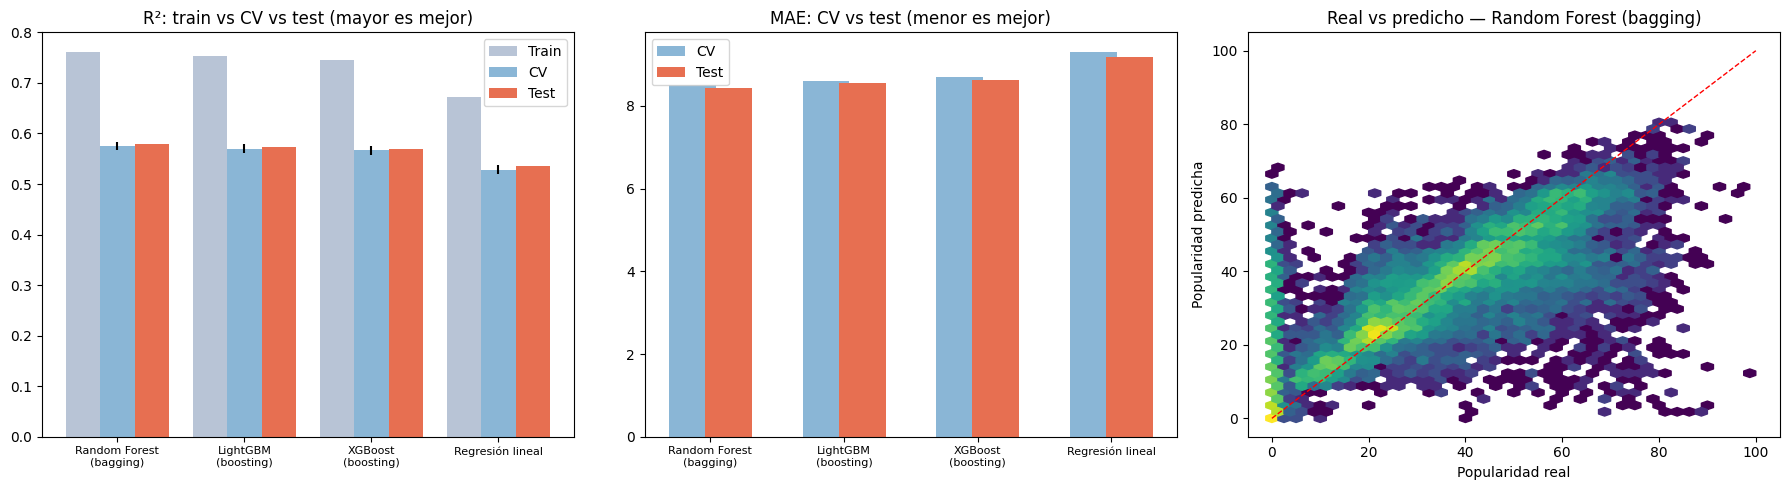

In [ ]:
# ---------- 2) Panel visual ----------
orden = tabla.index.tolist()
mejor_nombre = orden[0]
colores = ["#e76f51" if n == mejor_nombre else "#8ab6d6" for n in orden]

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# (a) R² train / CV / test
x = np.arange(len(orden)); w = 0.27
ax[0].bar(x - w, tabla["R² train"], w, label="Train", color="#b8c4d6")
ax[0].bar(x,     tabla["R² CV"],    w, yerr=tabla["± std CV"], label="CV", color="#8ab6d6")
ax[0].bar(x + w, tabla["R² test"],  w, label="Test", color="#e76f51")
ax[0].set_xticks(x); ax[0].set_xticklabels([o.replace(" (", "\n(") for o in orden], fontsize=8)
ax[0].set_title("R²: train vs CV vs test (mayor es mejor)"); ax[0].legend()

# (b) MAE CV vs test
ax[1].bar(x - w/2, tabla["MAE CV"],   w*1.3, label="CV",   color="#8ab6d6")
ax[1].bar(x + w/2, tabla["MAE test"], w*1.3, label="Test", color="#e76f51")
ax[1].set_xticks(x); ax[1].set_xticklabels([o.replace(" (", "\n(") for o in orden], fontsize=8)
ax[1].set_title("MAE: CV vs test (menor es mejor)"); ax[1].legend()

# (c) Real vs predicho del mejor modelo
pred_mejor = buscadores[mejor_nombre][0].predict(X_test)
ax[2].hexbin(y_test, pred_mejor, gridsize=40, cmap="viridis", mincnt=1, bins="log")
ax[2].plot([0, 100], [0, 100], "r--", lw=1)
ax[2].set_xlabel("Popularidad real"); ax[2].set_ylabel("Popularidad predicha")
ax[2].set_title(f"Real vs predicho — {mejor_nombre}")

plt.tight_layout(); plt.show()

Los modelos de ensamble explican cerca del 57% de la variabilidad de la popularidad, con un error medio de unos 8,5 puntos sobre 100, y rinden igual en validación cruzada que en test, por lo que generalizan de forma estable. Predicen bien las canciones de popularidad media, pero subestiman los grandes éxitos.

#Importancia de las variables

Las importaciones creadas aqui guardarlas en el pc o agregarlas al github porque interactuan en segmentacion

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Random Forest,LightGBM,XGBoost
artista_principal,0.661,0.652,0.636
track_genre,0.145,0.151,0.151
loudness,0.008,0.007,0.007
duration_s,0.007,0.006,0.006
energy,0.008,0.005,0.005
instrumentalness,0.008,0.005,0.005
acousticness,0.006,0.004,0.004
danceability,0.005,0.003,0.003
speechiness,0.003,0.002,0.003
liveness,0.002,0.003,0.002


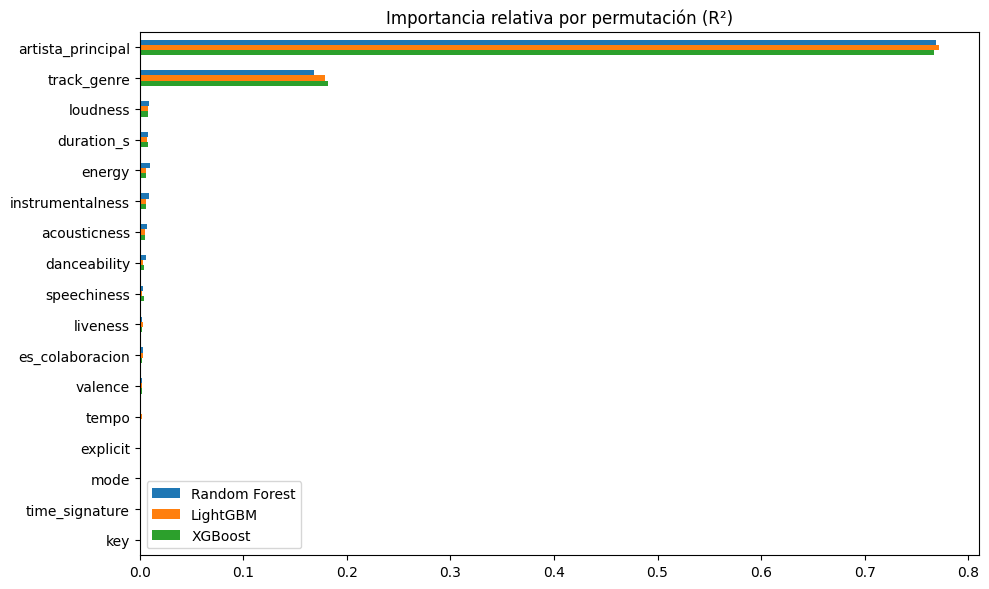

In [ ]:
import os
os.makedirs("data", exist_ok=True)

Xs = X_test.sample(5000, random_state=42)
ys = y_test.loc[Xs.index]

imp = {}
for nombre in ["Random Forest (bagging)", "LightGBM (boosting)", "XGBoost (boosting)"]:
    modelo = buscadores[nombre][0]
    pi = permutation_importance(modelo, Xs, ys, n_repeats=5, random_state=42,
                                scoring="r2", n_jobs=-1)
    imp[nombre.split(" (")[0]] = pd.Series(pi.importances_mean, index=Xs.columns)

imp = pd.DataFrame(imp).sort_values("XGBoost", ascending=False)   # aumento de R2 al permutar la variable
display(imp.round(3))

# recalcular SIEMPRE desde el imp recién cargado
imp_norm = imp.clip(lower=0)
imp_norm = imp_norm.div(imp_norm.sum())
ax = imp_norm.plot(kind="barh", figsize=(10, 6))
ax.invert_yaxis()
plt.title("Importancia relativa por permutación (R²)")
plt.tight_layout(); plt.show()

In [ ]:
res = pd.DataFrame({"track_id": df.loc[X_test.index, "track_id"].values,
                    "popularity": y_test.values})
for nombre, col in [("Regresión lineal", "pred_rl"), ("Random Forest (bagging)", "pred_rf"),
                    ("LightGBM (boosting)", "pred_lgbm"), ("XGBoost (boosting)", "pred_xgb")]:
    res[col] = buscadores[nombre][0].predict(X_test)
res.to_csv("data/predicciones_test.csv", index=False)
tabla.to_csv("data/tabla_comparacion_modelos.csv")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


#Limitaciones y consideraciones eticas

- **Fuga potencial por artista:** `artista_principal` es el predictor más fuerte, pero aproximadamente 8 de cada 10 artistas del test también están en train . El modelo aprende "quién es el artista", no solo "cómo suena la canción"; el desempeño es optimista para artistas nuevos.
- **Sesgo de popularidad:** el modelo reproduce y refuerza el sesgo de visibilidad (artistas ya famosos tienden a recibir predicciones altas), lo que perjudica a artistas emergentes si se usa para recomendar o priorizar contenido.
- **Uso responsable:** no debe usarse como único criterio para decisiones de inversión o de exposición; se recomienda un modelo alternativo sin artista para el descubrimiento de talento nuevo.
